In [1]:
from helper_files.maoa_plate_loader import *
from helper_files.mea_feats_analysis import *
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



In [2]:


root_dir = "/Users/blancamartin/Downloads/Sandra_MAOA_MEA/"  # adjust as needed
big_df = summarize_all_spike_files(root_dir, show_progress=True)





Recording date folders:   0%|          | 0/29 [00:00<?, ?it/s]

Processing 04.14.2025 / MAOA2 (1 files)
Processing 04.14.2025 / MAOA3 (1 files)
Processing 04.14.2025 / MAOA1 (1 files)
Processing 04.18.2025 / MAOA2 (1 files)
Processing 04.18.2025 / MAOA3 (1 files)
Processing 04.18.2025 / MAOA1 (1 files)
Processing 04.21.2025 / MAOA2 (1 files)
Processing 04.21.2025 / MAOA3 (1 files)
Processing 04.21.2025 / MAOA1 (1 files)
Processing 04.25.2025 / MAOA2 (1 files)
Processing 04.25.2025 / MAOA3 (1 files)
Processing 04.25.2025 / MAOA1 (1 files)
Processing 05.02.2025 / MAOA2 (1 files)
Processing 05.02.2025 / MAOA3 (1 files)
Processing 05.02.2025 / MAOA1 (1 files)
Processing 05.09.2025 / MAOA2 (1 files)
Processing 05.09.2025 / MAOA3 (1 files)
Processing 05.09.2025 / MAOA1 (1 files)
Processing 05.16.2025 / MAOA2 (1 files)
Processing 05.16.2025 / MAOA3 (1 files)
Processing 05.16.2025 / MAOA1 (1 files)
Processing 05.30.2025 / MAOA2 (1 files)
Processing 05.30.2025 / MAOA3 (1 files)
Processing 05.30.2025 / MAOA1 (1 files)
Processing 06.13.2025 / MAOA2 (1 files)


In [3]:
#add experiment group
big_df["experiment"] = big_df.apply(
    lambda row: assign_experiment(row["plate_name"], row["recording_date"]),
    axis=1
)

### Exp 3 analysis 

In [4]:
df3 = big_df[big_df["experiment"] == "Exp3"].copy()

df3["firing_mean_hz"] = df3["firing_rate_stats_hz"].str[0]
df3["firing_std_hz"]  = df3["firing_rate_stats_hz"].str[1]
df3["plate_well"] = df3["plate_name"] + "_" + df3["well"]




In [11]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

def plot_plate_map(df, plate_name):
    """Draw a 3×4 plate map showing cell line labels in each well."""

    sub = df[df["plate_name"] == plate_name].copy()
    if sub.empty:
        print(f"No data found for plate {plate_name}")
        return

    # Take one row per well (ignoring dates)
    sub = sub.drop_duplicates(subset=["well"]).copy()

    # Parse row and column
    sub["row"] = sub["well"].str[0]
    sub["col"] = sub["well"].str[1:].astype(int)

    # Order rows like A,B,C
    row_order = ["A", "B", "C"]
    sub["row_index"] = sub["row"].map({r:i for i,r in enumerate(row_order)})

    fig, ax = plt.subplots(figsize=(6,4))

    # categorical color map — stable colors per cell line
    cell_lines = sorted(sub["cell_line"].unique())
    color_map = {cl: plt.cm.Set3(i / len(cell_lines)) for i, cl in enumerate(cell_lines)}

    # Draw wells
    for _, r in sub.iterrows():
        x = r["col"] - 1       # 0-based
        y = r["row_index"]     # 0-based

        rect = patches.Rectangle(
            (x, y), 1, 1,
            linewidth=1,
            edgecolor='black',
            facecolor=color_map[r["cell_line"]]
        )
        ax.add_patch(rect)

        # Label inside the well
        ax.text(
            x + 0.5, y + 0.5,
            r["cell_line"],
            ha='center', va='center', fontsize=12
        )

    ax.set_xlim(0, 4)
    ax.set_ylim(0, 3)

    ax.set_xticks([0.5, 1.5, 2.5, 3.5])
    ax.set_xticklabels([1,2,3,4])

    ax.set_yticks([0.5, 1.5, 2.5])
    ax.set_yticklabels(row_order)

    ax.set_title(f"{plate_name} — Cell Line Layout")
    ax.invert_yaxis()  # so A is at top
    ax.set_aspect('equal')
    plt.tight_layout()
    plt.show()


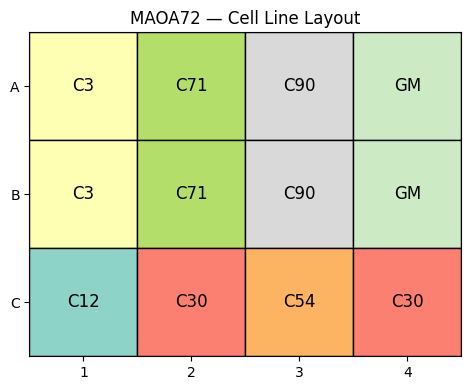

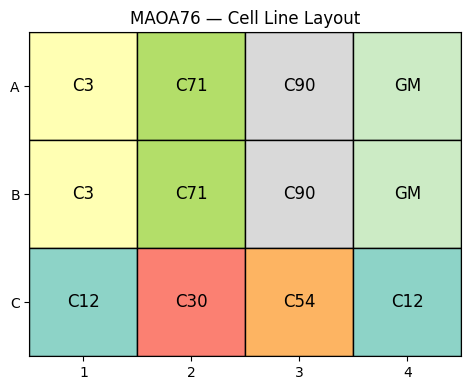

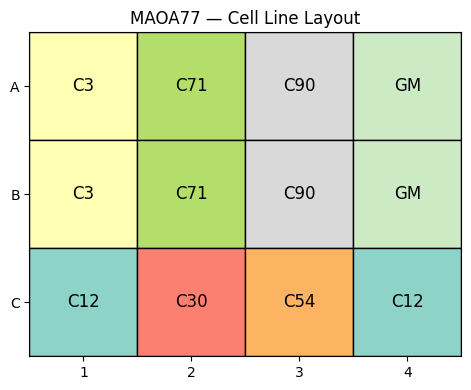

In [12]:
plot_plate_map(df3, "MAOA72")
plot_plate_map(df3, "MAOA76")
plot_plate_map(df3, "MAOA77")


In [13]:
#Extract electrode info

# firing threshold activty = 5 spikes per minute
threshold_hz = 5 / 60


df3_elec = pd.concat([expand_electrodes(r) for _, r in df3.iterrows()], ignore_index=True)


# Remove NaNs (silent electrodes)
df3_elec = df3_elec.dropna(subset=["firing_rate_hz"])
df3_elec = df3_elec[df3_elec["firing_rate_hz"] >= threshold_hz].copy()

# For plotting
df3_elec["date_label"] = df3_elec["recording_date"].astype(str)


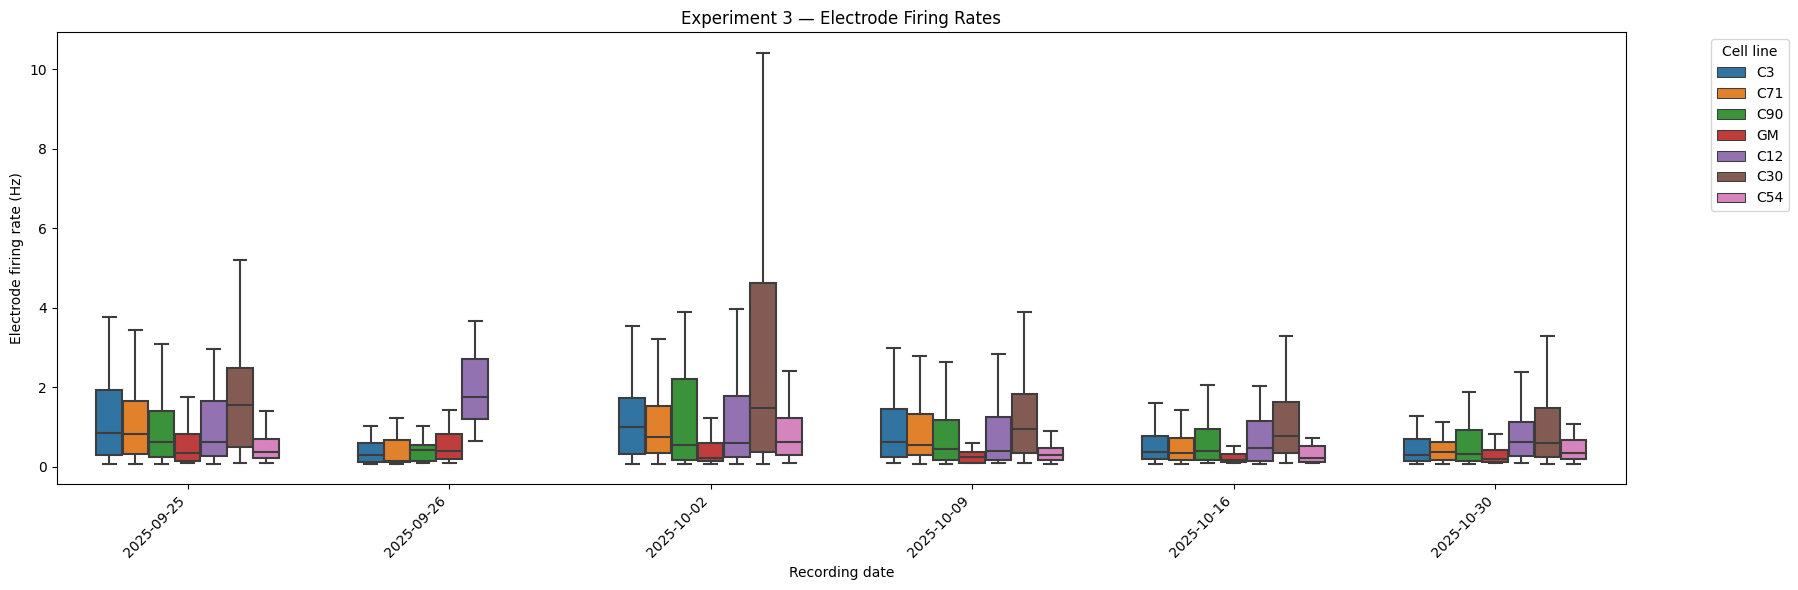

In [15]:
#firing rate electrode
# Labels for plotting
df3_elec["date_label"] = df3_elec["recording_date"].astype(str)
df3_elec["cell_line"] = df3_elec["cell_line"].astype(str)

# ---------------------------------------
#                BOX PLOT
# ---------------------------------------
plt.figure(figsize=(18, 6))

sns.boxplot(
    data=df3_elec,
    x="date_label",
    y="firing_rate_hz",
    hue="cell_line",
    showfliers=False,    # hide extreme outliers; you can turn on if needed
    width=0.7
)

plt.title("Experiment 3 — Electrode Firing Rates")
plt.xlabel("Recording date")
plt.ylabel("Electrode firing rate (Hz)")
plt.xticks(rotation=45, ha="right")

plt.legend(title="Cell line", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()






#can't find the data for Plate 72 for the 26th of September 



### Visualize firing rate results 

In [ ]:

# unpack firing stats
big_df["firing_mean_hz"] = big_df["firing_rate_stats_hz"].str[0]
big_df["firing_std_hz"]  = big_df["firing_rate_stats_hz"].str[1]






In [ ]:
#Split into 3 batches/experiments
plot_experiment_firing(big_df, "Exp1")
plot_experiment_firing(big_df, "Exp2")
plot_experiment_firing(big_df, "Exp3")

In [ ]:
age_bins = pd.cut(big_df["organoid_age_days"], bins=[0, 80, 130, 180, 230, 280],
                  labels=["<80","80–130","130–180","180–230","230–280"])
big_df["age_bin"] = age_bins

big_df.groupby(["cell_line","age_bin"])["firing_mean_hz"].mean().unstack()


In [ ]:
import matplotlib.pyplot as plt

# ---------- 3a. Boxplot by cell line ----------
fig, ax = plt.subplots(figsize=(6,4))

order = sorted(big_df["cell_line"].dropna().unique())
data = [big_df.loc[big_df["cell_line"] == cl, "firing_mean_hz"].dropna()
        for cl in order]

ax.boxplot(data, labels=order, showfliers=True)
ax.set_ylabel("Mean firing rate per well (Hz)")
ax.set_xlabel("Cell line")
ax.set_title("Well-averaged firing rate by cell line")

plt.tight_layout()

# ---------- 3b. Age vs firing (scatter) ----------
fig, ax = plt.subplots(figsize=(6,4))

for cl in order:
    sub = big_df[big_df["cell_line"] == cl]
    ax.scatter(sub["organoid_age_days"], sub["firing_mean_hz"],
               alpha=0.5, label=cl)

ax.set_xlabel("Organoid age (days)")
ax.set_ylabel("Mean firing rate per well (Hz)")
ax.set_title("Firing rate vs organoid age")
ax.legend(frameon=False, fontsize=8)

plt.tight_layout()


In [ ]:
big_df.groupby("cell_line")["firing_mean_hz"].describe()


In [ ]:
### Visualize bursting rate results 

In [ ]:
#unpack
big_df["burst_mean_hz"] = big_df["burst_rate_stats_hz"].str[0]
big_df["burst_std_hz"]  = big_df["burst_rate_stats_hz"].str[1]

In [ ]:
### Visualize network event results 

In [ ]:
### Visualize synchrony results 